# Homework 3
Due Wednesday Oct 23, 11:59pm (EST)

Rachel Liu

Teammates: ??

### 1: Eigenface for face recognition. (45 pts)

In [1]:
import numpy as np                 
import pandas as pd                
import imageio.v3 as iio           
from matplotlib import pylab as plt
import matplotlib.cm as cm         
%matplotlib inline

import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier     
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor

# Fix the random seed so every run of the notebook gives the same results
SEED = 9999
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


#### (a) Download the data

In [3]:
# Read the txt files into pd DataFrames. Columns are separated by whitespace.
train_df = pd.read_csv("faces/train.txt", sep=r"\s+", header=None, names=["path", "label"])
test_df = pd.read_csv("faces/test.txt", sep=r"\s+", header=None, names=["path", "label"])

# Print shape
print("train.txt shape:", train_df.shape)
print("test.txt shape:", test_df.shape)

# Taking a look at the first few rows
train_df.head()

train.txt shape: (540, 2)
test.txt shape: (100, 2)


,path,label
0,./faces/images/person01_63.png,1
1,./faces/images/person01_14.png,1
2,./faces/images/person01_09.png,1
3,./faces/images/person01_05.png,1
4,./faces/images/person01_01.png,1


#### (b) Load the training set into a matrix X
There are 540 training images in total, each has
50 × 50 pixels that need to be concatenated into a 2500-dimensional vector. So the size of X
should be 540 × 2500, where each row is a flattened face image. Pick a face image from X and
display that image in grayscale. Do the same thing for the test set. The size of matrix Xtest for
the test set should be 100 × 2500.


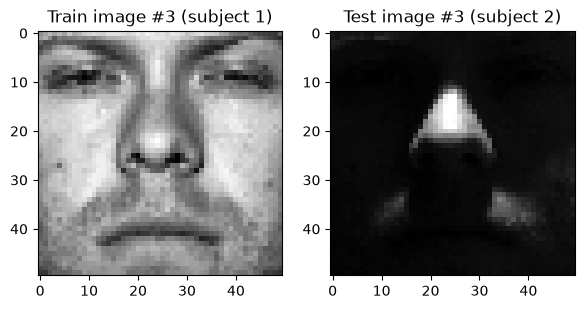

In [17]:
import numpy as np
import imageio.v3 as iio
from matplotlib import pylab as plt
import matplotlib.cm as cm
%matplotlib inline

# Loading data from training set
train_labels, train_data = [], []
for line in open('./faces/train.txt'):
    im = iio.imread(line.strip().split()[0])
    train_data.append(im.reshape(2500,))
    train_labels.append(line.strip().split()[1])
train_data, train_labels = np.array(train_data, dtype=float), np.array(train_labels, dtype=int)

# Loading data from test set
test_data, test_labels = [], []
for line in open('./faces/test.txt'):
    im = iio.imread(line.strip().split()[0])
    test_data.append(im.reshape(2500,))
    test_labels.append(line.strip().split()[1])
test_data, test_labels = np.array(test_data, dtype=float), np.array(test_labels, dtype=int)

# Plot image 3 from both set
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(train_data[3, :].reshape(50, 50), cmap=cm.Greys_r)
axes[0].set_title(f"Train image #3 (subject {train_labels[10]})")
axes[1].imshow(test_data[3, :].reshape(50, 50), cmap=cm.Greys_r)
axes[1].set_title(f"Test image #3 (subject {test_labels[10]})")
plt.tight_layout()
plt.show()

#### (c) Average Face
Compute the average face μ from the whole training set by summing up
every row in X then dividing by the number of faces. Display the average face as a grayscale
image.

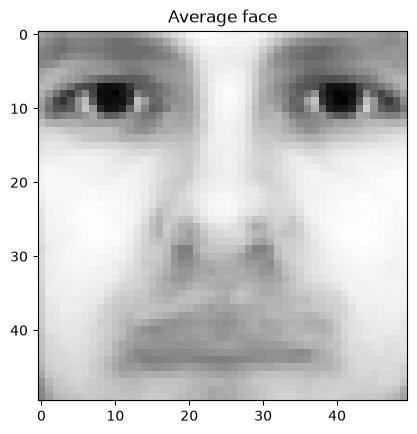

In [20]:
# Sum every row of X and divide by the number of faces (= mean over axis 0).
mu = train_data.sum(axis=0) / train_data.shape[0]

plt.imshow(mu.reshape(50, 50), cmap=cm.Greys_r)
plt.title("Average face")
plt.show()

#### (d) Mean Subtraction
Mean Subtraction. Subtract average face $\mathbf{\mu}$ from every row in $\mathbf{X}$. That is, $\mathbf{x_i} := \mathbf{x_i} - \mathbf{\mu}$, where $\mathbf{x_i}$ is the $i$-th row of $\mathbf{X}$. Pick a face image after mean subtraction from the new $\mathbf{X}$ and display that image in grayscale. Do the same thing for the test set $\mathbf{X_{test}}$ using the pre-computed average face $\mathbf{\mu}$ in (c).

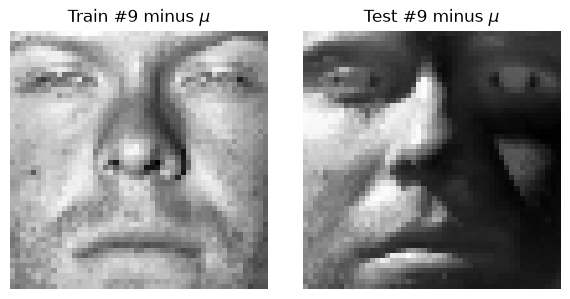

In [23]:
# Subtracting mu from X and X_test
X = train_data - mu
X_test = test_data - mu

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(X[9, :].reshape(50, 50), cmap=cm.Greys_r)
axes[0].set_title("Train #9 minus $\\mu$")
axes[1].imshow(X_test[9, :].reshape(50, 50), cmap=cm.Greys_r)
axes[1].set_title("Test #9 minus $\\mu$")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

#### (e) Eigenface
Perform eigendecomposition on $\mathbf{X}^T\mathbf{X} = \mathbf{V} \mathbf{\Lambda} \mathbf{V}^T$ to get eigenvectors $\mathbf{V}^T$,
where each row of $\mathbf{V}^T$ has the same dimension as the face image.
We refer to $\mathbf{v_i}$, the $i$-th row of $\mathbf{V}^T$, as $i$-th eigenface.
Display the first $10$ eigenfaces as $10$ images in grayscale.

X^T X shape: (2500, 2500)
V^T shape: (2500, 2500)
Top 5 eigenvalues: [1.95699366e+09 1.66123903e+09 2.56520395e+08 1.22558276e+08
 7.49887929e+07]


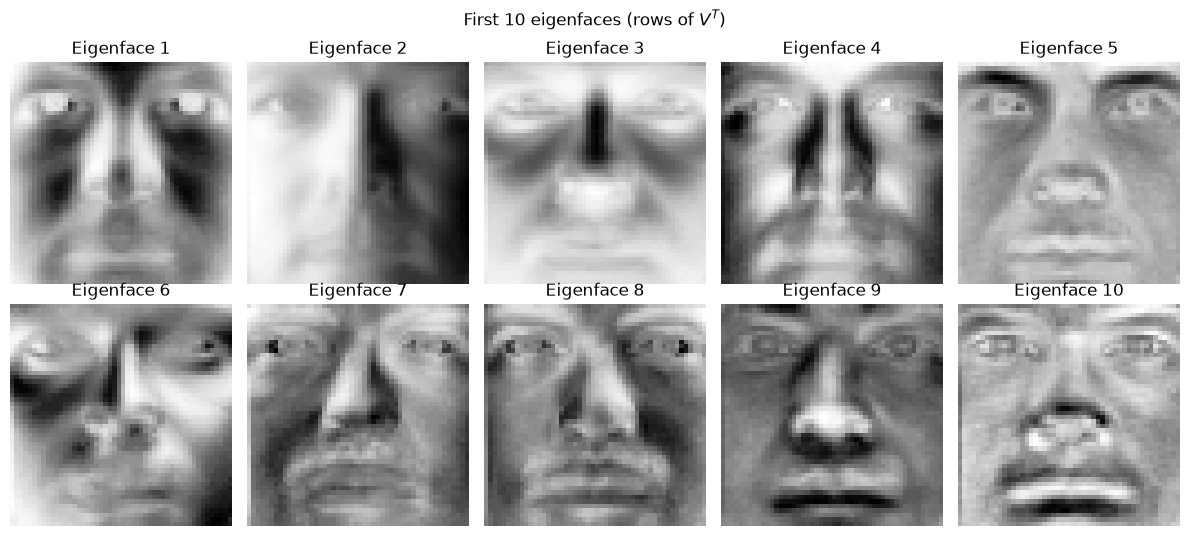

In [26]:
# X^T X is a 2500 x 2500 symmetric matrix
XtX = X.T @ X
print("X^T X shape:", XtX.shape)

# Use np.linalg.eigh for symmetric matrices to returns eigenvalues and eigenvectors. 
# Returns in ascending order, so flip to descending order.
eigvals, eigvecs = np.linalg.eigh(XtX)
order = np.argsort(eigvals)[::-1]         
eigvals = eigvals[order]
V = eigvecs[:, order]                     # columns of V are eigenvectors
VT = V.T                                  # rows of V^T are the eigenfaces v_1, v_2, ...

print("V^T shape:", VT.shape)
print("Top 5 eigenvalues:", np.round(eigvals[:5], 1))

# Display the first 10 eigenfaces as 50x50 grayscale images
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(VT[i].reshape(50, 50), cmap=cm.Greys_r)
    ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")
plt.suptitle("First 10 eigenfaces (rows of $V^T$)")
plt.tight_layout()
plt.show()

#### (f) Eigenface Feature
The top $r$ eigenfaces $\mathbf{V}^T[:r, :] = \{ v_1, v_2, \dots, v_r \}^T$ span an $r$-dimensional linear subspace of the original image space called \emph{face space}, whose origin is the average face $\mathbf{\mu}$, and whose axes are the eigenfaces $\{ v_1, v_2, \dots, v_r \}$.
Therefore, using the top $r$ eigenfaces $\{ v_1, v_2, \dots, v_r \}$, we can represent a $2500$-dimensional face image $\mathbf{z}$ as an $r$-dimensional feature vector $\mathbf{f}$: $\mathbf{f} = \mathbf{V}^T[:r, :]~ \mathbf{z} = [v_1, v_2, \dots, v_r]^T \mathbf{z}$.
Write a function to generate $r$-dimensional feature matrix $\mathbf{F}$ and $\mathbf{F_{test}}$ for training images $\mathbf{X}$ and test images $\mathbf{X_{test}}$, respectively (to get $\mathbf{F}$, multiply $\mathbf{X}$ to the transpose of first $r$ rows of $\mathbf{V}^T$, $\mathbf{F}$ should have same number of rows as $\mathbf{X}$ and $r$ columns; similarly for $\mathbf{X_{test}}$).

In [37]:
def eigenface_features(X_centered, VT, r):
    '''
    eigenface_features(X_centered, VT, r) projects mean-subtracted faces onto the top-r eigenfaces.

    X_centered : (n, 2500) faces with the average face already subtracted
    VT         : (2500, 2500) matrix whose rows are eigenfaces sorted by eigenvalue
    r          : number of eigenfaces (dimension of the face space)

    Returns F with shape (n, r): row i holds the coordinates of face i in face space,
    f_i = V^T[:r, :] @ z_i  for each row z_i.
    '''
    return X_centered @ VT[:r, :].T

# Example with r = 10
F = eigenface_features(X, VT, 10)
F_test = eigenface_features(X_test, VT, 10)
print(f"F      shape: { F.shape }, should have { X.shape[0] } columns and 10 rows")             # (540, 10)
print(f"F_test shape: { F_test.shape }, should have { X_test.shape[0] } columns and 10 rows")   # (100, 10)

F      shape: (540, 10), should have 540 columns and 10 rows
F_test shape: (100, 10), should have 100 columns and 10 rows


#### (g) Face Recognition
Face Recognition. For this problem, you are welcome to use libraries such as scikit
learn to perform logistic regression. Extract training and test features for r = 10. Train a
Logistic Regression model using F and test on Ftest. Report the classification accuracy on the
test set. Plot the classification accuracy on the test set as a function of r when r = 1, 2, . . . , 200.
Use “one-vs-rest” logistic regression, where a classifier is trained for each possible output
label. Each classifier is trained on faces with that label as positive data and all faces with
other labels as negative data. sklearn calls this the “ovr” mode.

In [36]:
def ovr_accuracy(r):
    '''Train one-vs-rest logistic regression on r-dim eigenface features, return test accuracy.'''
    # From previous cell, project the mean-subtracted faces onto the top-r eigenfaces to get r-dim features.
    F = eigenface_features(X, VT, r)
    F_test = eigenface_features(X_test, VT, r)
    # Use “one-vs-rest” logistic regression, where a classifier is trained for each possible output label.
    # Each classifier is trained on faces with that label as positive data and all faces with other labels as negative data.
    # max_iter is raised because the raw projection values are large and lbfgs needs more steps.
    clf = OneVsRestClassifier(LogisticRegression(max_iter=10000))
    clf.fit(F, train_labels)
    return clf.score(F_test, test_labels)   # fraction of test faces classified correctly

# Accuracy for r = 10
acc_10 = ovr_accuracy(10)
print(f"Test accuracy with r = 10: {acc_10:.2%}")

Test accuracy with r = 10: 80.00%


#### (h) Low-Rank Data Loss
These feature matrices $\mathbf{F}$ can be mapped back to their original dimensions; however, information is lost in the process and only approximations $\mathbf{X'}$ will be recovered.  This is done by multiplying the feature matrices $\mathbf{F}$ once again by the first $r$ rows of $\mathbf{V}^T$.  Plot the Frobenius distance $d(\mathbf{X}, \mathbf{X'}) = \sqrt{\mathrm{tr}\left( (\mathbf{X}-\mathbf{X'})^T (\mathbf{X}-\mathbf{X'}) \right)}$ between the original data $\mathbf{X}$ and their approximations $\mathbf{X'}$, over $r=1,2,...,200$.

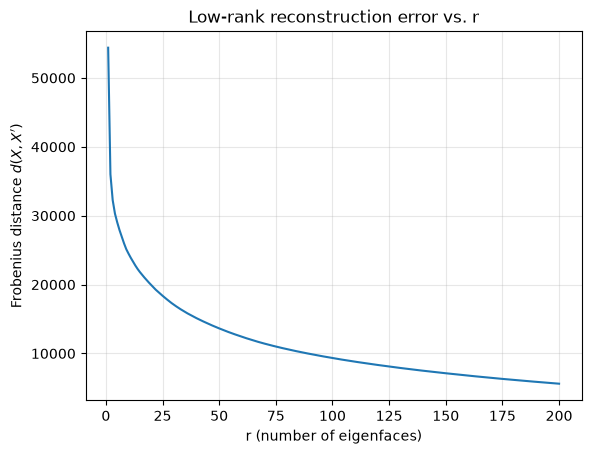

In [43]:
def reconstruction_distance(X_centered, VT, r):
    '''Frobenius distance between X and its rank-r reconstruction X' = F V^T[:r, :].'''
    F = eigenface_features(X_centered, VT, r)     # (n, r) compressed representation
    X_approx = F @ VT[:r, :]                      # map back to 2500 dims -> (n, 2500) to approximate
    diff = X_centered - X_approx
    return np.linalg.norm(diff, 'fro')

# Reminder, r_values are the number of eigenfaces we keep, so r = 1 is image compressed into 1 eig, 
# 200 is the image compressed into 200 eigs (so more accurate to original)
r_values = np.arange(1, 201)
distances = np.array([reconstruction_distance(X, VT, r) for r in r_values])

plt.plot(r_values, distances)
plt.xlabel("r (number of eigenfaces)")
plt.ylabel("Frobenius distance $d(X, X')$")
plt.title("Low-rank reconstruction error vs. r")
plt.grid(alpha=0.3)
plt.show()

### 2: Random Forests for Image Approximation. (25 pts)
In this question, you will use random forest regression to approximate an image by learning a function, $f : \mathbb{R}^2 \to \mathbb{R}$ , that takes \emph{image $(x,y)$ coordinates} as input and outputs \emph{pixel brightness}. This way, the function learns to approximate areas of the image that it has not seen before.

#### (a) Read and display the image
Start with an image of the Mona Lisa. If you don't like the Mona Lisa, pick another interesting image of your choice. Read and display the image. 

Image shape (height, width, channels): (703, 1250, 3)  dtype: uint8


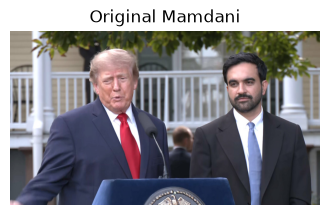

In [44]:
# Read the image as an (height, width, 3) uint8 RGB array
mamdani = iio.imread("mamdani.jpg")
H, W, C = mamdani.shape
print("Image shape (height, width, channels):", mamdani.shape, " dtype:", mamdani.dtype)

plt.figure(figsize=(4, 6))
plt.imshow(mamdani)
plt.title("Original Mamdani")
plt.axis("off")
plt.show()

#### (b) Data preprocessing
To build your ``training set'', sample 5,000 random $(x,y)$ coordinate locations uniformly across the entire image. Later, we will use all pixels in the image as the ''test set''.
Sample pixel values at each of the given coordinate locations. Each pixel contains red, green, and blue intensity values, so decide how you want to handle this. There are several options available to you:
* Convert the image to grayscale
* Regress all three values at once, so your function maps $(x,y)$ coordinates to $(r,g,b)$ values: $f : \mathbb{R}^2 \to \mathbb{R}^3$
* Learn a different function for each channel, $f_{Red} : \mathbb{R}^2 \to \mathbb{R}$, and likewise for $f_{Green}$, $f_{Blue}$.

Note that you may want to rescale the pixel intensities to lie between 0.0 and 1.0. (The default for pixel values may be between 0 and 255, but your image library may have different defaults.)

What other preprocessing steps are necessary for random regression forest outputs? Describe them, implement them, and justify your decisions.

In [ ]:
rng = np.random.default_rng(SEED)

# 1) RESCALE: Rescale the pixel intensities to lie between 0.0 and 1.0. 
# (The default for pixel values may be between 0 and 255, but your image library may have different defaults.)
# This is because imshow expects floats in [0, 1] for RGB, and the regression targets become nicely bounded.
img = mamdani.astype(float) / 255.0

# 2) SAMPLE: Sample 5,000 random $(x,y)$ coordinate locations uniformly across the entire image. 
# Later, we will use all pixels in the image as the ''test set''.
N_TRAIN = 5000
flat_idx = rng.choice(H * W, size=N_TRAIN, replace=False)
rows, cols = np.unravel_index(flat_idx, (H, W))

# 3) REGRESS ALL THREE: I choose to regress all 3 at once because we want to rebuilt in color
# Inputs: (x, y) coordinates of each sampled pixel.  We use x = column, y = row.
X_train_img = np.column_stack([cols, rows]).astype(float)       # shape (5000, 2)
# Training targets: the (r, g, b) value at those coordinates -> f: R^2 -> R^3
y_train_img = img[rows, cols, :]                                 # shape (5000, 3)

# 4) TEST GRID: Creates the test grid where every pixel coordinate (H*W points) is listed row by row
#    so that predictions can be reshaped straight back into an (H, W, 3) image. 
#    .ravel() flattens array of any shape into single row. 
all_rows, all_cols = np.mgrid[0:H, 0:W]
X_all_img = np.column_stack([all_cols.ravel(), all_rows.ravel()]).astype(float)  # (H*W, 2)

#### (c) Build the final image with a random forest
Source: https://github.com/kuleshov/cornell-cs5785-2025-applied-ml's 2025's AML GitHub repo's Lecture 15 (decision trees, bagging, random forests). 

Random forest (100 trees, depth 15): MSE vs. full image = 0.0089


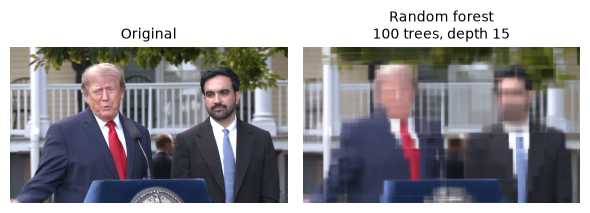

In [54]:
# Defining into functions so we can call for different models. 
def render(model):
    '''Fit `model` on the 5,000 sampled pixels, predict EVERY pixel, return an (H, W, 3) image + MSE.'''
    model.fit(X_train_img, y_train_img)
    pred = model.predict(X_all_img).reshape(H, W, 3)    # row-major order matches the grid
    mse = np.mean((pred - img) ** 2)                   # error against the full true image
    return pred, mse


def show_grid(images, titles, ncols=None, figsize_per=(3, 4.5)):
    '''Display several images side by side.'''
    n = len(images)
    ncols = ncols or n
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_per[0] * ncols, figsize_per[1] * nrows))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, im, t in zip(np.ravel(axes), images, titles):
        ax.imshow(im)
        ax.set_title(t, fontsize=10)
    plt.tight_layout()
    plt.show()


# A random forest with 100 trees of depth 15 (n_jobs=-1 uses all CPU cores)
rf = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=SEED, n_jobs=-1)
rf_img, rf_mse = render(rf)
print(f"Random forest (100 trees, depth 15): MSE vs. full image = {rf_mse:.4f}")

show_grid([img, rf_img], ["Original", "Random forest\n100 trees, depth 15"])

#### (d) Experimentation
##### i. A single decision tree with depth 1, 2, 3, 5, 10, 15

depth  1:     2 leaves (max possible     2), MSE = 0.0501
depth  2:     4 leaves (max possible     4), MSE = 0.0445
depth  3:     8 leaves (max possible     8), MSE = 0.0394
depth  5:    32 leaves (max possible    32), MSE = 0.0327
depth 10:   600 leaves (max possible  1024), MSE = 0.0193
depth 15:  2587 leaves (max possible 32768), MSE = 0.0140


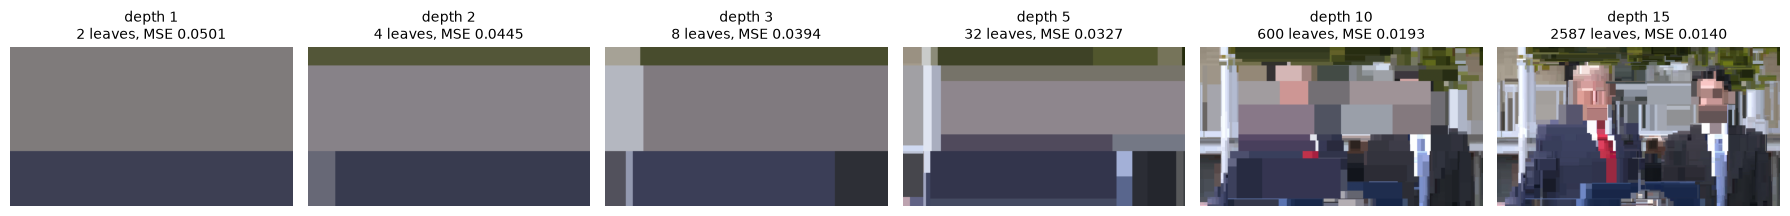

In [55]:
depths = [1, 2, 3, 5, 10, 15]
depth_imgs, depth_titles = [], []
for d in depths:
    # n_estimators=1 -> a "forest" containing a single tree.
    # bootstrap=False so the single tree sees all 5,000 samples
    model = RandomForestRegressor(n_estimators=1, max_depth=d, bootstrap=False, random_state=SEED)
    pred, mse = render(model)
    n_leaves = model.estimators_[0].get_n_leaves()
    depth_imgs.append(pred)
    depth_titles.append(f"depth {d}\n{n_leaves} leaves, MSE {mse:.4f}")
    print(f"depth {d:>2}: {n_leaves:>5} leaves (max possible {2 ** d:>5}), MSE = {mse:.4f}")

show_grid(depth_imgs, depth_titles, ncols=6)

##### ii. Random forest of depth 7 with 1, 3, 5, 10, 100 trees

  1 trees: MSE = 0.0267
  3 trees: MSE = 0.0247
  5 trees: MSE = 0.0242
 10 trees: MSE = 0.0230
100 trees: MSE = 0.0229


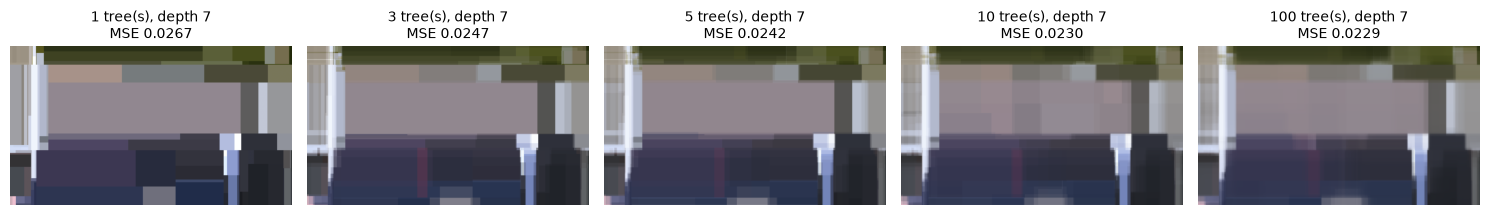

In [57]:
n_trees_list = [1, 3, 5, 10, 100]
tree_imgs, tree_titles = [], []
for n in n_trees_list:
    # Default bootstrap=True: each tree is trained on a different bootstrap sample of the
    # 5,000 pixels, so the trees disagree a little and averaging them smooths the result.
    model = RandomForestRegressor(n_estimators=n, max_depth=7, random_state=SEED, n_jobs=-1)
    pred, mse = render(model)
    tree_imgs.append(pred)
    tree_titles.append(f"{n} tree(s), depth 7\nMSE {mse:.4f}")
    print(f"{n:>3} trees: MSE = {mse:.4f}")

show_grid(tree_imgs, tree_titles, ncols=5)

##### iii. Baseline: $k$-NN regressor with $k=1$

1-NN: MSE = 0.0129


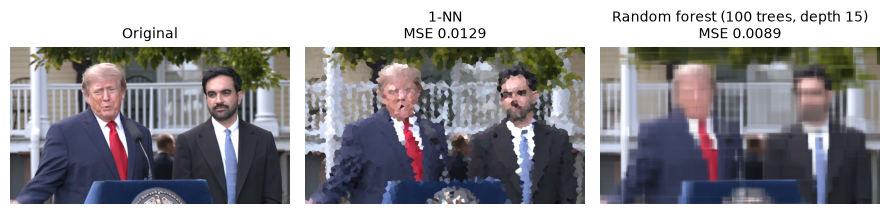

In [59]:
# k = 1: every pixel gets the color of its single nearest sampled pixel (Euclidean distance in (x, y)).
knn = KNeighborsRegressor(n_neighbors=1)
knn_img, knn_mse = render(knn)
print(f"1-NN: MSE = {knn_mse:.4f}")

show_grid([img, knn_img, rf_img],
          ["Original", f"1-NN\nMSE {knn_mse:.4f}", f"Random forest (100 trees, depth 15)\nMSE {rf_mse:.4f}"])

##### iv. Pruning strategies
We compare several ways of limiting tree growth (pre-pruning) and scikit-learn's minimal cost-complexity post-pruning (`ccp_alpha`). All use a single unpruned-depth tree (no `max_depth`) so the effect of each strategy is isolated.

No pruning                :  4639 leaves, depth 28, MSE = 0.0142
min_samples_leaf = 7      :   577 leaves, depth 19, MSE = 0.0141
max_leaf_nodes = 512      :   512 leaves, depth 19, MSE = 0.0145


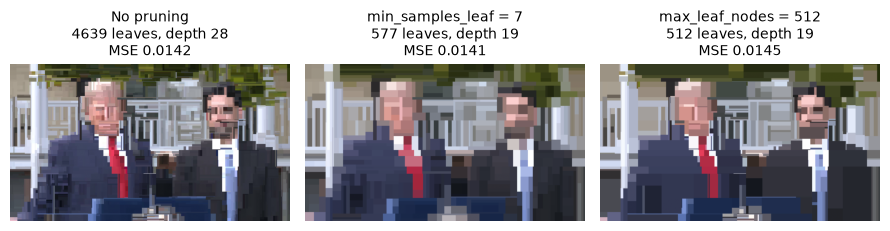

In [67]:
# Each entry: (description, keyword arguments for a single DecisionTreeRegressor)
pruning_configs = [
    ("No pruning", {}),
    ("min_samples_leaf = 7", {"min_samples_leaf": 7}),
    ("max_leaf_nodes = 512", {"max_leaf_nodes": 512}),
]

prune_imgs, prune_titles = [], []
for name, kwargs in pruning_configs:
    tree = DecisionTreeRegressor(random_state=SEED, **kwargs)
    pred, mse = render(tree)
    prune_imgs.append(pred)
    prune_titles.append(f"{name}\n{tree.get_n_leaves()} leaves, depth {tree.get_depth()}\nMSE {mse:.4f}")
    print(f"{name:<26}: {tree.get_n_leaves():>5} leaves, depth {tree.get_depth():>2}, MSE = {mse:.4f}")

show_grid(prune_imgs, prune_titles, ncols=3)